## Project 2

## SEED = 560192899

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import erf
from scipy.integrate import quad

from mp2lib import (
    inv_cdf_exponential,
    inv_cdf_rayleigh,
    sample_by_inversion,
    ks_statistic
)

SEED = 560192899 #created on 11/02/2026
rng = np.random.default_rng(SEED)

rng_step1 = rng.spawn(1)[0]
rng_step2 = rng.spawn(1)[0]
rng_step3 = rng.spawn(1)[0]

N = 10**5
critical_value = 1.36 / np.sqrt(N)

print(f"95% KS critical value: {critical_value:.6f}")

95% KS critical value: 0.004301


## Step 1: From CDF to density

### Uniform distribution on [0, 1]

The support is

$$
0 \leq x \leq 1
$$

The CDF is

$$
F_X(x)=
\begin{cases}
0, & x<0,\\
x, & 0\leq x\leq 1\\
1, & x>1
\end{cases}
$$

The PDF is

$$
f_X(x)=
\begin{cases}
1, & 0\leq x\leq 1\\
0, & \text{otherwise}
\end{cases}
$$

### Exponential distribution

$$
F_X(x)=1-e^{-x}
$$

$$
f_X(x)=e^{-x} \qquad x\geq 0
$$

### Standard Gaussian distribution

$$
F_X(x)=\Phi(x)
$$

$$
f_X(x)=\frac{1}{\sqrt{2\pi}}e^{-x^2/2}
$$

### Rayleigh distribution

$$
F_X(x)=1-e^{-x^2/2}
$$

$$
f_X(x)=xe^{-x^2/2} \qquad x\geq 0
$$

In [22]:
def uniform_cdf(x):
    return np.where(x < 0, 0, np.where(x <= 1, x, 1))

def uniform_pdf(x):
    return np.where((x >= 0) & (x <= 1), 1, 0)

def exponential_cdf(x):
    return np.where(x >= 0, 1 - np.exp(-x), 0)

def exponential_pdf(x):
    return np.where(x >= 0, np.exp(-x), 0)

def gaussian_cdf(x):
    return stats.norm.cdf(x)

def gaussian_pdf(x):
    return stats.norm.pdf(x)

def rayleigh_cdf(x):
    return np.where(x >= 0, 1 - np.exp(-x**2 / 2), 0)

def rayleigh_pdf(x):
    return np.where(x >= 0, x * np.exp(-x**2 / 2), 0)

In [23]:
def uniform_cdf(x):
    return np.where(x < 0, 0, np.where(x <= 1, x, 1))

def uniform_pdf(x):
    return np.where((x >= 0) & (x <= 1), 1, 0)

def exponential_cdf(x):
    return np.where(x >= 0, 1 - np.exp(-x), 0)

def exponential_pdf(x):
    return np.where(x >= 0, np.exp(-x), 0)

def gaussian_cdf(x):
    return stats.norm.cdf(x)

def gaussian_pdf(x):
    return stats.norm.pdf(x)

def rayleigh_cdf(x):
    return np.where(x >= 0, 1 - np.exp(-x**2 / 2), 0)

def rayleigh_pdf(x):
    return np.where(x >= 0, x * np.exp(-x**2 / 2), 0)

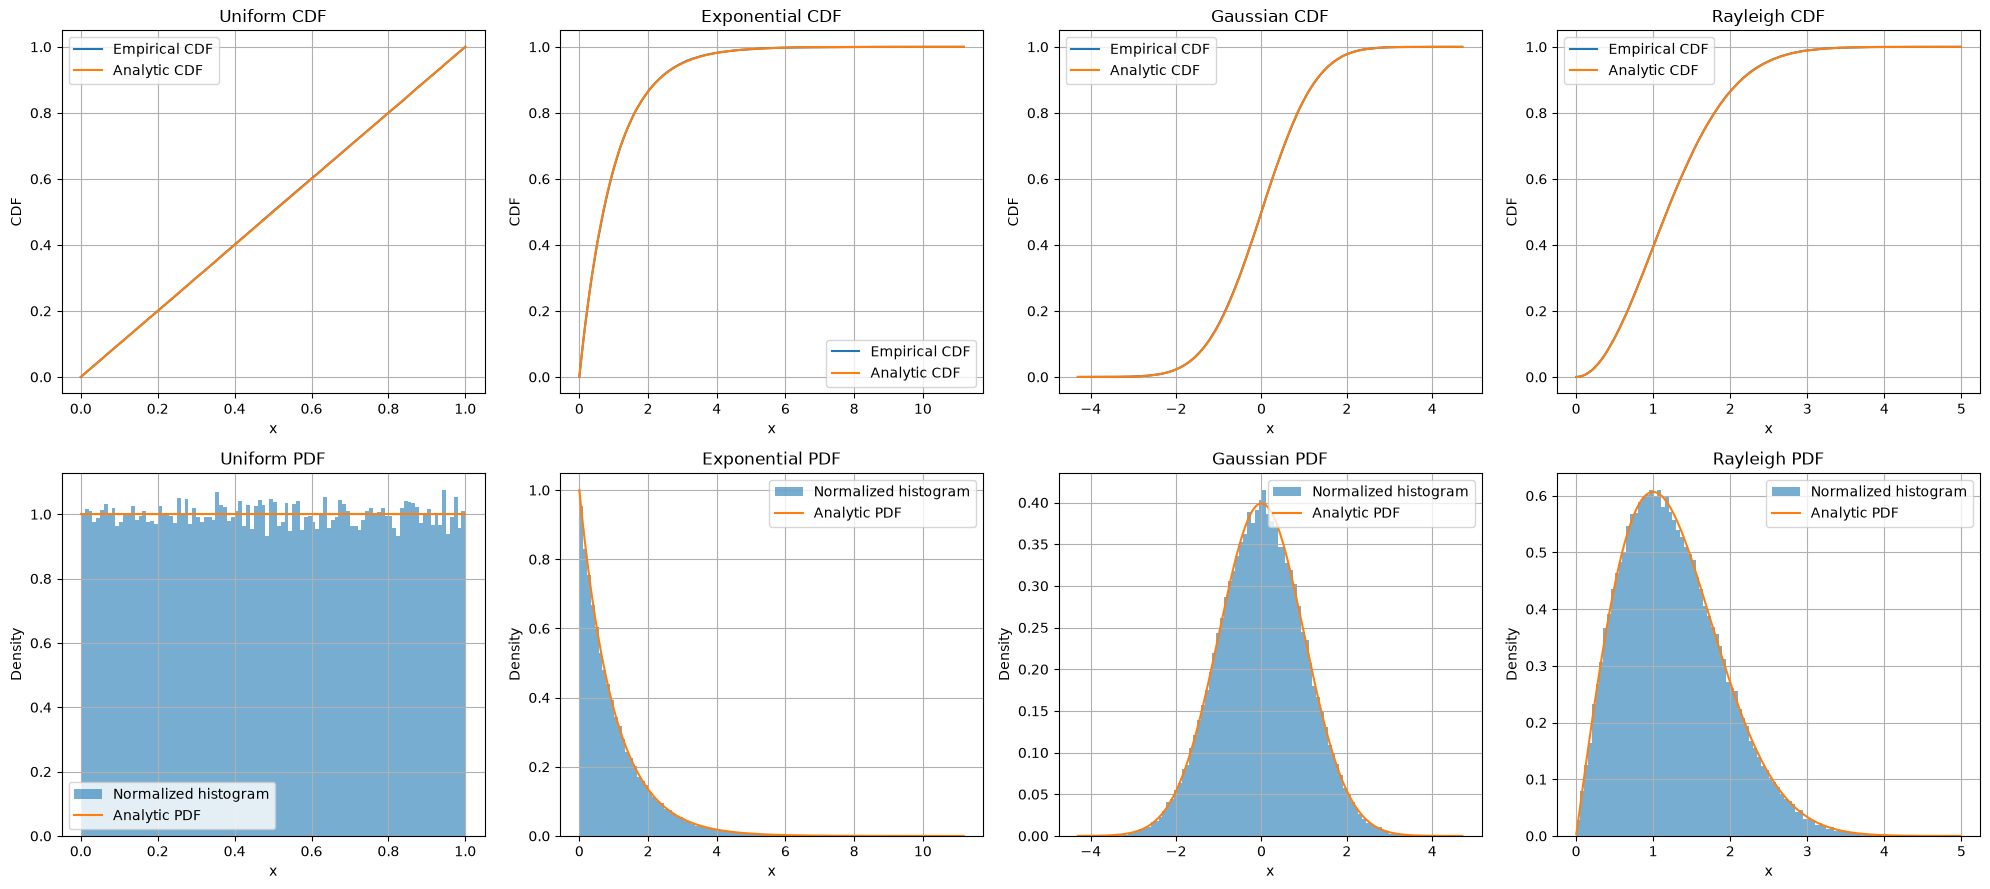

95% critical value = 0.004301
Uniform KS statistic = 0.001734
Exponential KS statistic = 0.004137
Gaussian KS statistic = 0.003057
Rayleigh KS statistic = 0.001679

Exponential theoretical values:
Mean = 1, Median = 0.6931, Variance = 1
Sample mean = 1.000990, median = 0.700861, variance = 0.991236

Rayleigh theoretical values:
Mean = 1.2533, Median = 1.1774, Variance = 0.4292
Sample mean = 1.252295, median = 1.177535, variance = 0.428418


In [24]:
uniform_samples = rng_step1.random(N)
exponential_samples = rng_step1.exponential(scale=1, size=N)
gaussian_samples = rng_step1.normal(0, 1, N)
rayleigh_samples = rng_step1.rayleigh(scale=1, size=N)

distributions = [
    ("Uniform", uniform_samples, uniform_cdf, uniform_pdf),
    ("Exponential", exponential_samples, exponential_cdf, exponential_pdf),
    ("Gaussian", gaussian_samples, gaussian_cdf, gaussian_pdf),
    ("Rayleigh", rayleigh_samples, rayleigh_cdf, rayleigh_pdf)
]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))

for col, (name, samples, cdf, pdf) in enumerate(distributions):
    ordered = np.sort(samples)
    empirical = np.arange(1, N + 1) / N

    axes[0, col].plot(ordered, empirical, label="Empirical CDF")
    x = np.linspace(ordered.min(), ordered.max(), 1000)
    axes[0, col].plot(x, cdf(x), label="Analytic CDF")

    axes[0, col].set_title(name + " CDF")
    axes[0, col].set_xlabel("x")
    axes[0, col].set_ylabel("CDF")
    axes[0, col].legend()
    axes[0, col].grid(True)

    axes[1, col].hist(
        samples,
        bins=100,
        density=True,
        alpha=0.6,
        label="Normalized histogram"
    )

    axes[1, col].plot(x, pdf(x), label="Analytic PDF")
    axes[1, col].set_title(name + " PDF")
    axes[1, col].set_xlabel("x")
    axes[1, col].set_ylabel("Density")
    axes[1, col].legend()
    axes[1, col].grid(True)

plt.tight_layout()
plt.show()

print(f"95% critical value = {critical_value:.6f}")

for name, samples, cdf, pdf in distributions:
    print(f"{name} KS statistic = {ks_statistic(samples, cdf):.6f}")

print("\nExponential theoretical values:")
print("Mean = 1, Median = 0.6931, Variance = 1")
print(
    f"Sample mean = {np.mean(exponential_samples):.6f}, "
    f"median = {np.median(exponential_samples):.6f}, "
    f"variance = {np.var(exponential_samples):.6f}"
)

print("\nRayleigh theoretical values:")
print("Mean = 1.2533, Median = 1.1774, Variance = 0.4292")
print(
    f"Sample mean = {np.mean(rayleigh_samples):.6f}, "
    f"median = {np.median(rayleigh_samples):.6f}, "
    f"variance = {np.var(rayleigh_samples):.6f}"
)

The exponential density is right-skewed and has a long positive tail, which pulls the mean above the median. The Gaussian density is symmetric, so its mean and median are equal.

## Step 2: Build your own generator by inversion

Let \(U\) be uniformly distributed on \([0,1]\), and let \(F\) be a continuous strictly increasing CDF. Define

$$
Y=F^{-1}(U)
$$

Then

$$
P(Y\leq y)
=
P(F^{-1}(U)\leq y)
=
P(U\leq F(y))
=
F(y)
$$

Therefore, \(F^{-1}(U)\) has CDF \(F\)

For the exponential distribution,

$$
u=1-e^{-\lambda x}
$$

$$
1-u=e^{-\lambda x}
$$

$$
x=-\frac{\ln(1-u)}{\lambda}
$$

For the Rayleigh distribution,

$$
u=1-e^{-x^2/(2\sigma^2)}
$$

$$
x=\sigma\sqrt{-2\ln(1-u)}
$$

Exponential inversion KS = 0.001418
Rayleigh inversion KS = 0.001532
95% critical value = 0.004301


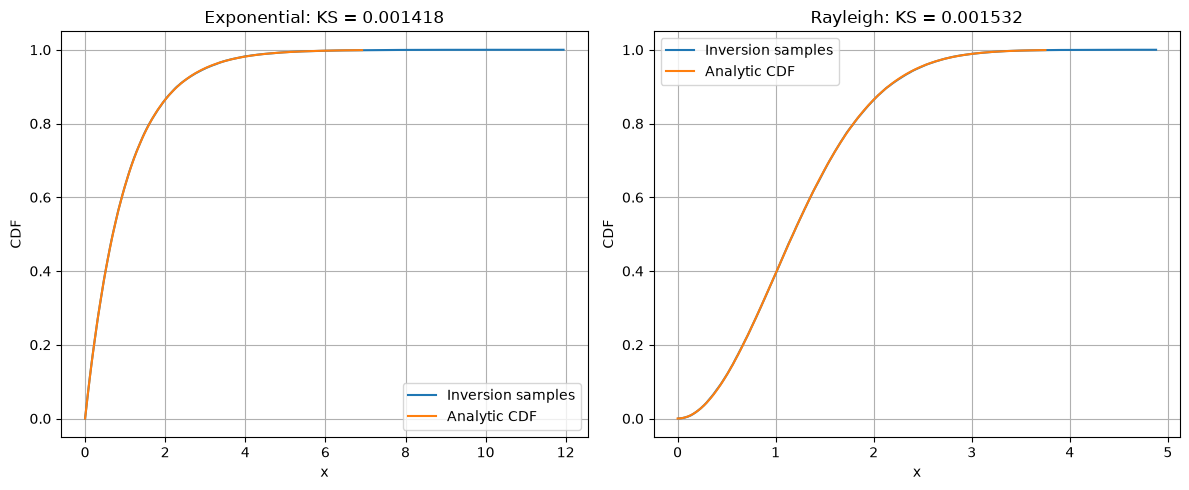

In [25]:
inversion_exponential = sample_by_inversion(
    inv_cdf_exponential,
    N,
    rng_step2,
    lam=1
)

inversion_rayleigh = sample_by_inversion(
    inv_cdf_rayleigh,
    N,
    rng_step2,
    sigma=1
)

exp_ks = ks_statistic(inversion_exponential, exponential_cdf)
rayleigh_ks = ks_statistic(inversion_rayleigh, rayleigh_cdf)

print(f"Exponential inversion KS = {exp_ks:.6f}")
print(f"Rayleigh inversion KS = {rayleigh_ks:.6f}")
print(f"95% critical value = {critical_value:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name, samples, cdf, ks_value in [
    (axes[0], "Exponential", inversion_exponential, exponential_cdf, exp_ks),
    (axes[1], "Rayleigh", inversion_rayleigh, rayleigh_cdf, rayleigh_ks)
]:
    ordered = np.sort(samples)
    empirical = np.arange(1, N + 1) / N

    ax.plot(ordered, empirical, label="Inversion samples")

    x = np.linspace(0, np.percentile(samples, 99.9), 1000)
    ax.plot(x, cdf(x), label="Analytic CDF")

    ax.set_title(f"{name}: KS = {ks_value:.6f}")
    ax.set_xlabel("x")
    ax.set_ylabel("CDF")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

## Step 3: A function of a random variable

Let \(X\) be standard Gaussian and let

$$
Y=X^2.
$$

For \(y>0\),

$$
Y\leq y
\Longleftrightarrow
-\sqrt{y}\leq X\leq\sqrt{y}
$$

Therefore,

$$
F_Y(y)
=
P(-\sqrt{y}\leq X\leq\sqrt{y})
=
2\Phi(\sqrt{y})-1
$$

Differentiating gives

$$
f_Y(y)
=
\frac{1}{\sqrt{2\pi y}}e^{-y/2},
\qquad y>0
$$

The density becomes unbounded near zero because squaring compresses values around \(x=0\) into a very narrow interval around \(y=0\). The singularity is proportional to \(y^{-1/2}\), which is integrable, so the total area remains equal to one.

Integral of PDF = 1.000000000001


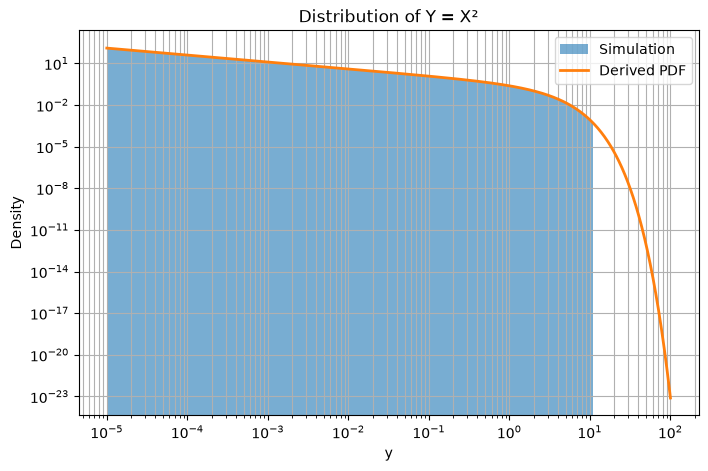

P(Y <= 1): theory=0.682689, empirical=0.682793
P(Y <= 0.1): theory=0.248170, empirical=0.248308
Median: theory=0.454936, empirical=0.456369
Mean: theory=1.000000, empirical=0.999182
Variance: theory=2.000000, empirical=1.990647
The log-log density slope near zero is -1/2.


In [26]:
def squared_gaussian_cdf(y):
    y = np.asarray(y)
    return np.where(y <= 0, 0, erf(np.sqrt(y / 2)))

def squared_gaussian_pdf(y):
    y = np.asarray(y, dtype=float)
    result = np.zeros_like(y)

    positive = y > 0
    result[positive] = (
        np.exp(-y[positive] / 2)
        / np.sqrt(2 * np.pi * y[positive])
    )

    return result

integral, error = quad(
    lambda z: np.exp(-z / 2) / np.sqrt(2 * np.pi * z),
    0,
    np.inf
)

print(f"Integral of PDF = {integral:.12f}")

y_samples = rng_step3.normal(0, 1, 10**6)**2

bins = np.logspace(
    -5,
    np.log10(np.percentile(y_samples, 99.9)),
    150
)

plt.figure(figsize=(8, 5))

plt.hist(
    y_samples,
    bins=bins,
    density=True,
    alpha=0.6,
    label="Simulation"
)

y_plot = np.logspace(-5, 2, 1000)

plt.plot(
    y_plot,
    squared_gaussian_pdf(y_plot),
    linewidth=2,
    label="Derived PDF"
)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("y")
plt.ylabel("Density")
plt.title("Distribution of Y = X²")
plt.legend()
plt.grid(True, which="both")
plt.show()

print(
    f"P(Y <= 1): theory={squared_gaussian_cdf(np.array([1.0]))[0]:.6f}, "
    f"empirical={np.mean(y_samples <= 1):.6f}"
)

print(
    f"P(Y <= 0.1): theory={squared_gaussian_cdf(np.array([0.1]))[0]:.6f}, "
    f"empirical={np.mean(y_samples <= 0.1):.6f}"
)

print(
    f"Median: theory={stats.norm.ppf(0.75)**2:.6f}, "
    f"empirical={np.median(y_samples):.6f}"
)

print(f"Mean: theory=1.000000, empirical={np.mean(y_samples):.6f}")
print(f"Variance: theory=2.000000, empirical={np.var(y_samples):.6f}")
print("The log-log density slope near zero is -1/2.")